In [1]:

import numpy as np 
import pandas as pd 
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import kagglehub


/kaggle/input/datasets/bahaabashtawi/dataset-4h-mm/XAU_4h_data.csv


In [2]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

def load_and_preprocess_data():
    df = pd.read_csv('XAU_4h_data.csv', sep=';')
    df = df.dropna().head(2000)  
    X = df[['Open']].values
    y = df['Close'].values
    
   
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)
    
   
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_poly)
    
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
    
    return X_scaled, y_scaled

Adam Final Cost: 0.0024202392358738615
Adam Final Theta: [0.         0.49977319 0.49795721]


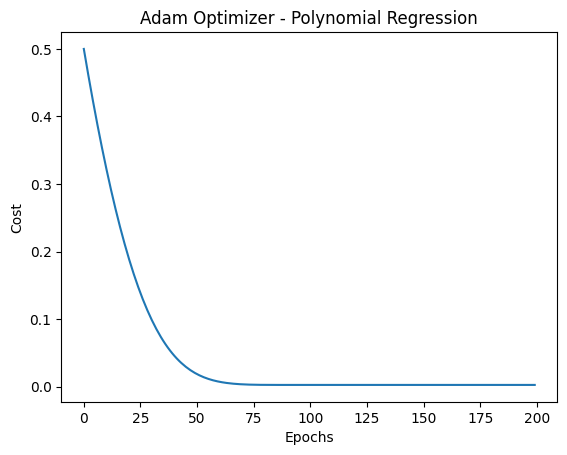

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
import glob

def load_and_preprocess_data():
    csv_files = glob.glob('/kaggle/input/**/XAU_4h_data.csv', recursive=True)
    file_path = csv_files[0] if csv_files else 'XAU_4h_data.csv'
    
    df = pd.read_csv(file_path, sep=';')
    df = df.dropna().head(2000)  
    X = df[['Open']].values
    y = df['Close'].values
    
    poly = PolynomialFeatures(degree=2)
    X_poly = poly.fit_transform(X)
    
    scaler_X = StandardScaler()
    X_scaled = scaler_X.fit_transform(X_poly)
    
    scaler_y = StandardScaler()
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).flatten()
    
    return X_scaled, y_scaled

X, y = load_and_preprocess_data()
m, n = X.shape

theta = np.zeros(n)
learning_rate = 0.01
beta1 = 0.9
beta2 = 0.999
epsilon = 1e-8

m_t = np.zeros(n)
v_t = np.zeros(n)
epochs = 200
costs = []

for t in range(1, epochs + 1):
    predictions = np.dot(X, theta)
    errors = predictions - y
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    costs.append(cost)
    
    gradient = (1 / m) * np.dot(X.T, errors)
    
    m_t = beta1 * m_t + (1 - beta1) * gradient
    v_t = beta2 * v_t + (1 - beta2) * (gradient ** 2)
    
    m_corrected = m_t / (1 - beta1 ** t)
    v_corrected = v_t / (1 - beta2 ** t)
    
    theta -= (learning_rate / (np.sqrt(v_corrected) + epsilon)) * m_corrected

print("Adam Final Cost:", costs[-1])
print("Adam Final Theta:", theta)

plt.plot(costs)
plt.title("Adam Optimizer - Polynomial Regression")
plt.xlabel("Epochs")
plt.ylabel("Cost")
plt.savefig("adam_cost.png")
plt.show()